# Jittered vs. fixed collocation grid — same problem, two training runs

`Workspace.train()` in `copula_constrained_wasserstein_velocity_field.py`
evaluates the continuity-equation loss on an `(n_point, n_point, n_point)`
cartesian grid in `(t, x1, x2)`. That grid can be built one of two ways,
switched by `compute_copula_vector_field(..., jitter_grid=...)`:

- **`jitter_grid=True`** the grid is rebuilt every
  iteration with each axis's anchors perturbed by up to half a grid cell
  around their regular `linspace` positions (stratified / jittered sampling).
  Training therefore never revisits the exact same finite point set, at the
  cost of recomputing both endpoints' density and log-density gradient on the
  new points every iteration.
- **`jitter_grid=False`** — the previous default, one fixed regular grid for the whole run, with the
  endpoint densities/gradients on it hoisted out of the loop and computed
  once. Cheaper per iteration, but the model is fit to the same
  `n_point**3` collocation points for up to `num_iterations` passes, so it can
  overfit *those points* rather than the underlying continuous PDE.

This notebook runs the same transport problem twice and compares (a) the resulting transport cost
`sqrt(mean |w|^2)` against the training-free bounds, (b) snapshots of the
interpolating copula at the same times `t` used in
`copula_vector_field_example.ipynb`, and (c) how the cost estimate evolved
across training checkpoints.

This notebook is meant to confirm the effect of jittering. Everything except `jitter_grid` is held fixed between the two runs. The early stopping criterion was disabled and a `num_iterations` was set to `100000` to ensure the training lasted long enough for potential overfitting to be visible.

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from torchdiffeq import odeint

import sys
sys.path.insert(0, str(Path.cwd().parent))  # project root, so the distance_calculation_campaign imports resolve

from distance_calculation_campaign.copula_families import load_target
from distance_calculation_campaign.copula_constrained_wasserstein_velocity_field import compute_copula_vector_field, device

print(device)

cuda:0


## The two endpoints

`c0 = Gumbel(12)` — a strongly upper-tail-dependent copula, mass squeezed
onto the diagonal with high density in the (1,1) corner, 
transported to `c1 = Independence`, the uniform density on the unit square.
So the whole job of the learned field is to spread concentrated mass out
evenly while every intermediate `c_t` stays a copula (uniform marginals).

In [2]:
sigma = 0.26

copula0 = load_target('GumbelCopula', 12, sigma).double().to(device)
copula1 = load_target('IndependenceCopula', None, sigma).double().to(device)

In [3]:
TRAIN_KWARGS = dict(
    n_point=21,                   # default is 11; 21 is the reference notebook's original resolution
    num_iterations=100000,        # default is 150000
    energy_plateau_rel_tol=0.005, # default is 0.008 -- stricter bar for declaring a plateau
    verbose=True,
)
SEED = 0

## Run A — jittered grid (`jitter_grid=True`)

In [4]:
torch.manual_seed(SEED)
t_start = time.perf_counter()
field_jitter = compute_copula_vector_field(copula0, copula1, jitter_grid=True, **TRAIN_KWARGS)
secs_jitter = time.perf_counter() - t_start
print(f"\njitter_grid=True: {secs_jitter/60:.1f} min")

/hkfs/home/haicore/ior/fi1281/copula_fade_wasserstein_distance_script.py:914: UserWarning: fade_distance: both copulas have negligible density over 66% of the domain, so the fade path spends much of its time moving mass through near-empty regions. L is still a valid finite length, but a large value here is real -- it is what the linear-mixture path genuinely costs, not a numerical artefact.
  warnings.warn(f"fade_distance: {msg}. L is still a valid finite "


fade-path upper bound: L_fade=0.4151 (compare against sqrt(loss_energy))


iteration 0/100000: loss=17.530 (loss_energy=0.000, loss_con=3.506, penalty_weight=5)


iteration 250/100000: loss=3.706 (loss_energy=0.336, loss_con=0.674, penalty_weight=5)


iteration 500/100000: loss=2.391 (loss_energy=0.285, loss_con=0.421, penalty_weight=5)


...

iteration 99000/100000: loss=0.312 (loss_energy=0.144, loss_con=0.034, penalty_weight=5)


iteration 99250/100000: loss=0.281 (loss_energy=0.120, loss_con=0.032, penalty_weight=5)


iteration 99500/100000: loss=0.260 (loss_energy=0.145, loss_con=0.023, penalty_weight=5)


iteration 99750/100000: loss=0.258 (loss_energy=0.128, loss_con=0.026, penalty_weight=5)


iteration 99999/100000: loss_energy still improving (rel. improvement 0.0085 >= cutoff 0.0050)
iteration 100000/100000: loss=0.307 (loss_energy=0.120, loss_con=0.037, penalty_weight=5)

jitter_grid=True: 75.8 min


## Run B — fixed grid (`jitter_grid=False`)

In [5]:
torch.manual_seed(SEED)
t_start = time.perf_counter()
field_fixed = compute_copula_vector_field(copula0, copula1, jitter_grid=False, **TRAIN_KWARGS)
secs_fixed = time.perf_counter() - t_start
print(f"\njitter_grid=False: {secs_fixed/60:.1f} min")

# checkpoints are saved every `window` iterations, so the last key is a proxy
# for how far each run actually got before its plateau-detector break (if any)
print(f"\ncheckpoints, jittered: {sorted(field_jitter.checkpoints)}")
print(f"checkpoints, fixed:    {sorted(field_fixed.checkpoints)}")
print(f"wall clock: jittered {secs_jitter/60:.1f} min vs fixed {secs_fixed/60:.1f} min "
      f"({secs_jitter/max(secs_fixed, 1e-9):.2f}x)")

/hkfs/home/haicore/ior/fi1281/copula_fade_wasserstein_distance_script.py:914: UserWarning: fade_distance: both copulas have negligible density over 66% of the domain, so the fade path spends much of its time moving mass through near-empty regions. L is still a valid finite length, but a large value here is real -- it is what the linear-mixture path genuinely costs, not a numerical artefact.
  warnings.warn(f"fade_distance: {msg}. L is still a valid finite "


fade-path upper bound: L_fade=0.4151 (compare against sqrt(loss_energy))
iteration 0/100000: loss=17.997 (loss_energy=0.000, loss_con=3.599, penalty_weight=5)


iteration 250/100000: loss=2.567 (loss_energy=0.314, loss_con=0.450, penalty_weight=5)


iteration 500/100000: loss=1.370 (loss_energy=0.310, loss_con=0.212, penalty_weight=5)


iteration 750/100000: loss=0.895 (loss_energy=0.296, loss_con=0.120, penalty_weight=5)


...

iteration 99000/100000: loss=0.142 (loss_energy=0.038, loss_con=0.021, penalty_weight=5)


iteration 99250/100000: loss=0.121 (loss_energy=0.038, loss_con=0.017, penalty_weight=5)


iteration 99500/100000: loss=0.136 (loss_energy=0.039, loss_con=0.019, penalty_weight=5)


iteration 99750/100000: loss=0.105 (loss_energy=0.038, loss_con=0.013, penalty_weight=5)


iteration 99999/100000: loss_energy still improving (rel. improvement 0.0665 >= cutoff 0.0050)
iteration 100000/100000: loss=0.154 (loss_energy=0.038, loss_con=0.023, penalty_weight=5)

jitter_grid=False: 74.1 min

checkpoints, jittered: [10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]
checkpoints, fixed:    [10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000]
wall clock: jittered 75.8 min vs fixed 74.1 min (1.02x)


## Starting particles: a percentile grid over `c0`

Both fields are driven with the *same* deterministic particle set, so any
difference in the snapshots below is the field's, not sampling noise.


In [6]:
npts_t = 50
npts_grid = 100        # 100x100 percentile grid
n_fine = 8000          # resolution of the conditional-CDF integration (Gumbel(12) is sharply peaked)
eps = 1e-6

p = (torch.arange(npts_grid, dtype=torch.float64) + 0.5) / npts_grid  # percentile levels
u_marg = p
v_fine = torch.linspace(eps, 1 - eps, n_fine, dtype=torch.float64)

uu = u_marg.view(npts_grid, 1).expand(npts_grid, n_fine)
vv = v_fine.view(1, n_fine).expand(npts_grid, n_fine)
uv = torch.stack([uu, vv], dim=-1).to(device)

with torch.no_grad():
    c_vals = copula0.density_u(uv).cpu()

dv = v_fine[1:] - v_fine[:-1]
increments = 0.5 * (c_vals[:, 1:] + c_vals[:, :-1]) * dv          # trapezoidal rule
F = torch.cat([torch.zeros(npts_grid, 1, dtype=torch.float64), torch.cumsum(increments, dim=1)], dim=1)
F = F / F[:, -1:]  # int_0^1 c0(u, v) dv == 1 exactly; this only corrects the [0,eps]/[1-eps,1] truncation

v_grid = torch.from_numpy(
    np.stack([np.interp(p.numpy(), F[i].numpy(), v_fine.numpy()) for i in range(npts_grid)])
)
u_grid = u_marg.view(npts_grid, 1).expand(npts_grid, npts_grid)
u0 = torch.stack([u_grid, v_grid], dim=-1).reshape(-1, 2).double().to(device)

# the target c1 is Independence, whose percentile grid is exactly the regular
# grid -- no conditional inversion needed, since F(v | u) = v for every u
target_uv = torch.stack([u_grid, p.view(1, npts_grid).expand(npts_grid, npts_grid)], dim=-1).reshape(-1, 2).numpy()

t_grid = torch.linspace(0, 1, npts_t).to(device)
print(u0.shape, target_uv.shape)

torch.Size([10000, 2]) (10000, 2)


## Transport, and the square-rooted losses

`W_value[i]` is the mean squared copula-space speed `|w|^2` over the
particles at time `t_i`; averaging it over `t` gives an *action*, and its
square root is the copula-constrained Wasserstein distance.

In [7]:
def transport(field, u0, t_grid):
    # Push `u0` through `field` and return (samples_u, W_value).
    samples_u = odeint(field, u0, t=t_grid, method="dopri5", atol=1e-5, rtol=1e-5).cpu()
    W_value = torch.zeros(len(t_grid))
    for i in range(len(t_grid)):
        w = field(t_grid[i].to(device), samples_u[i].to(device))
        W_value[i] = (w ** 2).sum(1).mean()  # c-weighted, since grid cells are equal-mass under c0
    return samples_u, W_value


samples_jitter, W_jitter = transport(field_jitter, u0, t_grid)
samples_fixed, W_fixed = transport(field_fixed, u0, t_grid)

L_jitter = torch.sqrt(W_jitter.mean()).item()
L_fixed = torch.sqrt(W_fixed.mean()).item()

print(f"                            action        sqrt(action)")
print(f"jitter_grid=True       {W_jitter.mean():.6f}      {L_jitter:.6f}")
print(f"jitter_grid=False      {W_fixed.mean():.6f}      {L_fixed:.6f}")


                            action        sqrt(action)
jitter_grid=True       0.124421      0.352733
jitter_grid=False      0.032517      0.180326


## Snapshots of the interpolation

Same five times as `copula_vector_field_example.ipynb` —
indices `[0, 12, 24, 37, 49]` of a 50-point `linspace(0, 1)`, i.e.
`t ≈ 0, 0.24, 0.49, 0.76, 1`. Left column jittered, right column fixed; both
started from the identical particle set, so the rows are directly comparable.

The `t = 1` row is the one to read against the true target: `c1` is
Independence, so a converged run should land on a visually *uniform* square.

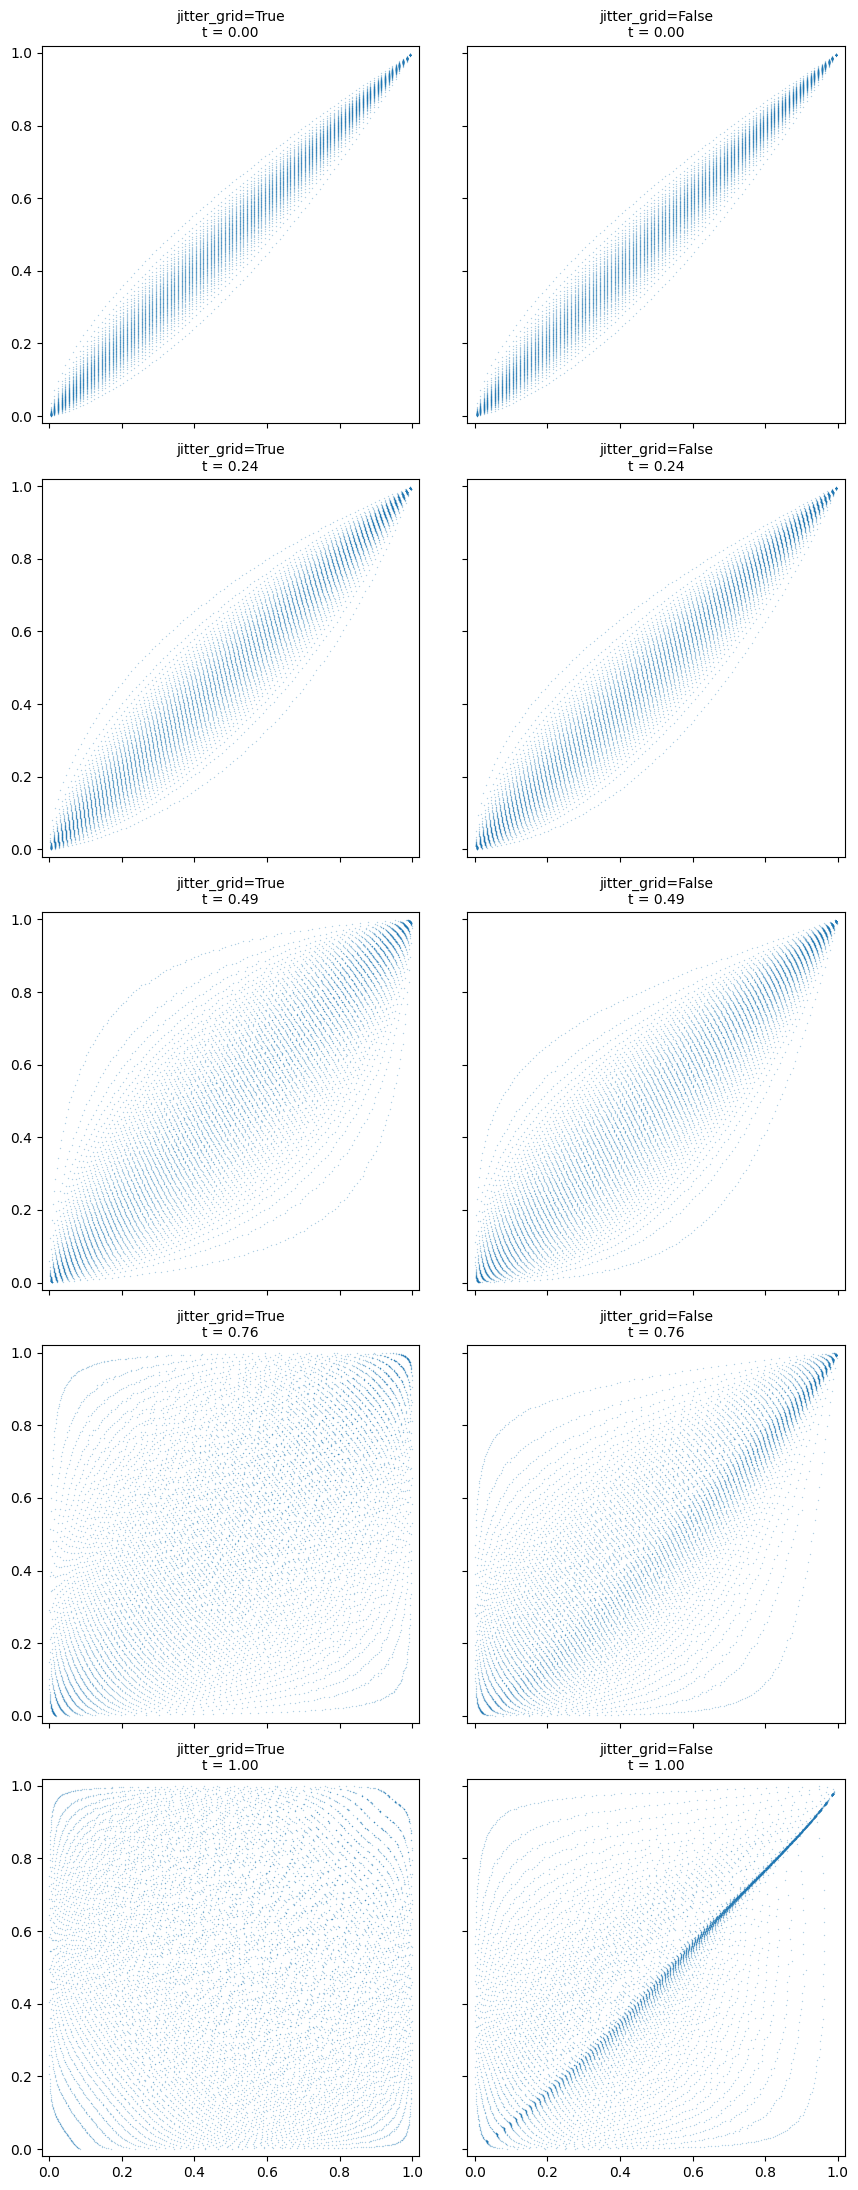

In [8]:
snapshot_idx = [0, 12, 24, 37, 49]
runs = [("jitter_grid=True", samples_jitter), ("jitter_grid=False", samples_fixed)]

fig, axes = plt.subplots(len(snapshot_idx), 2, figsize=(9, 4.4 * len(snapshot_idx)),
                         sharex=True, sharey=True)
for row, i in enumerate(snapshot_idx):
    for col, (name, samples) in enumerate(runs):
        pts = samples[i].detach().cpu().numpy()
        ax = axes[row, col]
        ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.35, linewidths=0)
        ax.set_title(f"{name}\nt = {t_grid[i].item():.2f}", fontsize=10)
        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_aspect("equal")
fig.tight_layout()
plt.show()

### Endpoints, for reference

The percentile grid of `c0 = Gumbel(12)` that both runs started from, and the
percentile grid of `c1 = Independence` that both should end on.

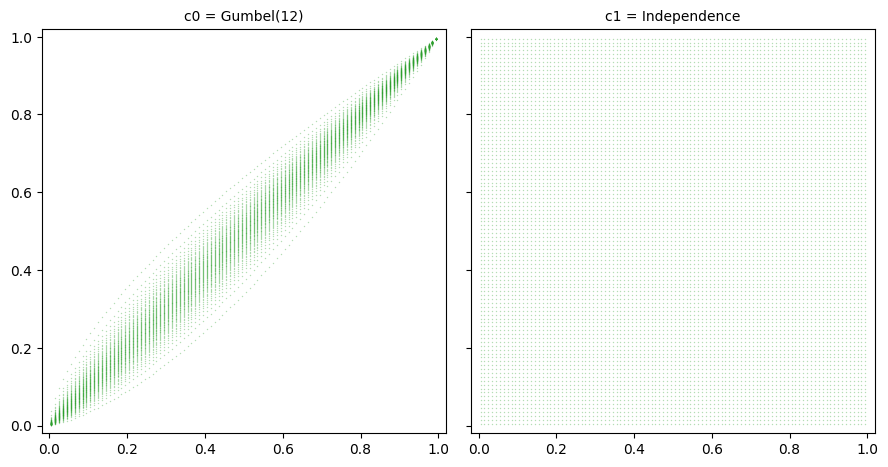

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharex=True, sharey=True)
for ax, pts, title in [(axes[0], u0.detach().cpu().numpy(), "c0 = Gumbel(12)"),
                       (axes[1], target_uv, "c1 = Independence")]:
    ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.35, linewidths=0, color="tab:green")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()

### Marginal uniformity at `t = 1`

Every `c_t` along the path is supposed to be a copula, i.e. to have uniform
marginals — that is the constraint the penalty term enforces, and the
histograms below are the most direct visual read on how well each run
actually met it at the far end of the path. Flatness matters more than the
scatter above: a run can produce a plausible-looking cloud whose marginals
have visibly drifted.

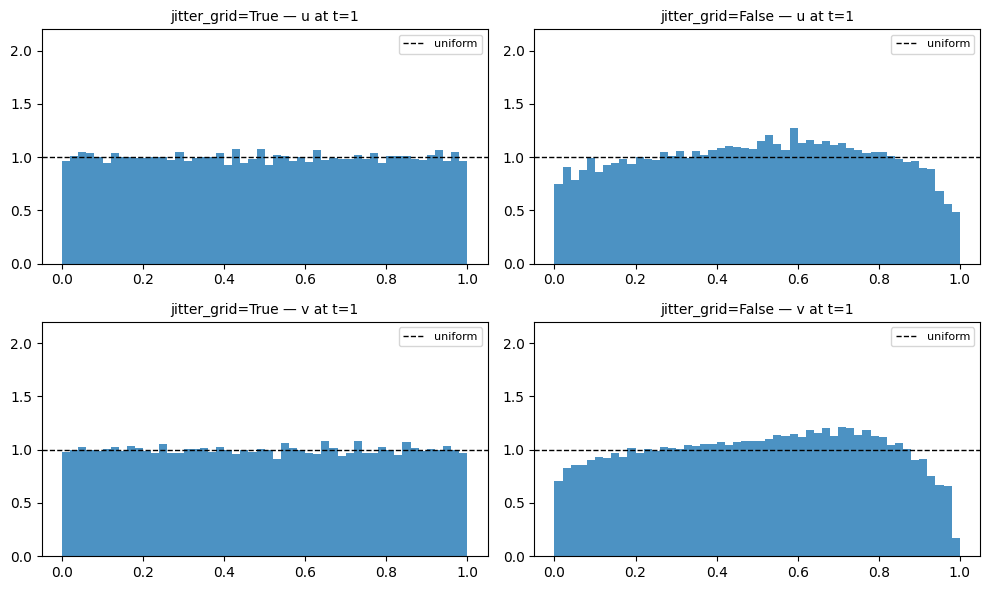

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for col, (name, samples) in enumerate(runs):
    pts = samples[-1].detach().cpu().numpy()
    for row, coord in enumerate(["u", "v"]):
        ax = axes[row, col]
        ax.hist(pts[:, row], bins=50, range=(0, 1), density=True, alpha=0.8)
        ax.axhline(1.0, color="k", ls="--", lw=1, label="uniform")
        ax.set_title(f"{name} — {coord} at t=1", fontsize=10)
        ax.set_ylim(0, 2.2)
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Cost estimate across training checkpoints

`Workspace.train()` snapshots its weights in memory roughly every `window`
iterations, and `field.field_at_checkpoint(i)` rebuilds a field from one of
them — i.e. "what would this run have produced had it stopped at iteration
`i`". Re-running the transport at each checkpoint shows how each run's cost
estimate converged, which is the part of the comparison the two final numbers
alone can't answer: whether jittering changes *where* the run lands, or only
how it gets there.

In [12]:
progressions = {}
for name, field, W_final in [("jitter_grid=True", field_jitter, W_jitter),
                             ("jitter_grid=False", field_fixed, W_fixed)]:
    prog = {}
    for ckpt_iter in sorted(field.checkpoints.keys()):
        field_ckpt = field.field_at_checkpoint(ckpt_iter)
        samples_ckpt, W_ckpt = transport(field_ckpt, u0, t_grid)
        prog[ckpt_iter] = torch.sqrt(W_ckpt.mean()).item()
        print(f"{name}  checkpoint {ckpt_iter}: sqrt(W_value.mean()) = {prog[ckpt_iter]:.4f}")
    # the final trained field, one iteration past the last checkpoint
    final_iter = (max(prog) + 1) if prog else 1
    prog[final_iter] = torch.sqrt(W_final.mean()).item()
    print(f"{name}  final: sqrt(W_value.mean()) = {prog[final_iter]:.4f}\n")
    progressions[name] = prog

jitter_grid=True  checkpoint 10000: sqrt(W_value.mean()) = 0.4320


jitter_grid=True  checkpoint 20000: sqrt(W_value.mean()) = 0.4108


jitter_grid=True  checkpoint 30000: sqrt(W_value.mean()) = 0.3905


jitter_grid=True  checkpoint 40000: sqrt(W_value.mean()) = 0.3866


jitter_grid=True  checkpoint 50000: sqrt(W_value.mean()) = 0.3740


...

jitter_grid=False  checkpoint 60000: sqrt(W_value.mean()) = 0.2406


jitter_grid=False  checkpoint 70000: sqrt(W_value.mean()) = 0.2255


jitter_grid=False  checkpoint 80000: sqrt(W_value.mean()) = 0.2098


jitter_grid=False  checkpoint 90000: sqrt(W_value.mean()) = 0.1949


jitter_grid=False  checkpoint 100000: sqrt(W_value.mean()) = 0.1805
jitter_grid=False  final: sqrt(W_value.mean()) = 0.1803



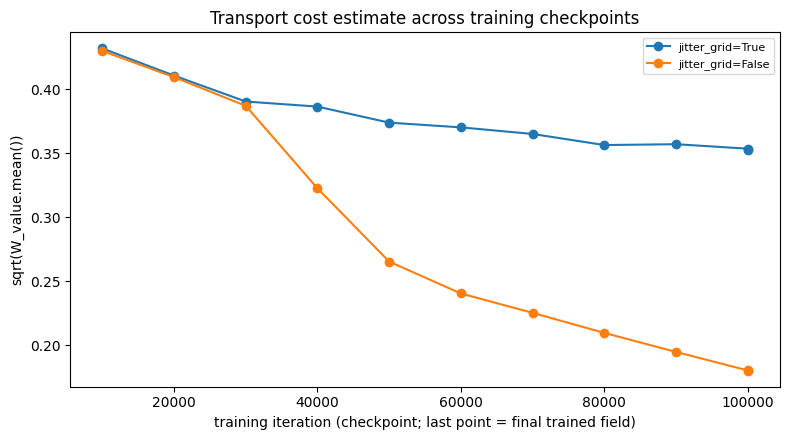

In [13]:
plt.figure(figsize=(8, 4.5))
for name, prog in progressions.items():
    plt.plot(list(prog.keys()), list(prog.values()), marker="o", label=name)
plt.xlabel("training iteration (checkpoint; last point = final trained field)")
plt.ylabel("sqrt(W_value.mean())")
plt.title("Transport cost estimate across training checkpoints")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Conclusion

Without jittering, the model clearly overfits the fixed collocation grid, starting around iteration 30000.

Up to that point the two runs are practically identical (0.4320 / 0.4300 at 10000, 0.3905 / 0.3872 at 30000). After it they separate. The jittered run keeps converging slowly and levels off at **0.353**. The fixed-grid run keeps dropping steeply and ends at **0.180**.

The fixed run's low value is not a better result. It is well below the unconstrained lower bound W2 ≈ 0.291 for this pair, and no copula-preserving path can be cheaper than unconstrained transport. The model has stopped solving the continuous problem and only satisfies the loss on its `21**3` fixed points. The resulting intermediate densities $(c_t)_{t > 0}$ are no longer copulas, and the final density $c_1$ after applying the velocity field does not resemble the specified independence density.

`jitter_grid=True` is therefore kept as the default.